# Pareto Four-Panel Composite

This notebook rebuilds a selected 2x2 Pareto composite from the current paper-artifact source rows. It is intended as the customization surface for panel choices, titles, colors, typography, legends, and annotation mode.

In [1]:
# Editable configuration
from pathlib import Path

SOURCE_VERSION = "v002_candidate"
ARTIFACT_ROOT = Path("experiments/paper_artifacts/pareto_figure") / SOURCE_VERSION
OUTPUT_DIR = ARTIFACT_ROOT / "four_panel_composite"

OASIS_SOURCE_CSV = ARTIFACT_ROOT / "oasis20_pareto_source_rows.csv"
LUNGCT_SOURCE_CSV = ARTIFACT_ROOT / "lungct10_pareto_source_rows.csv"
NICKNAME_CSV = Path("experiments/paper_artifacts/method_nicknames.csv")

OUTPUTS = {
    "no_annotations": {
        "filename": "pareto_four_panel_composite_no_annotations.png",
        "annotate": False,
    },
    "annotated_review": {
        "filename": "pareto_four_panel_composite_annotated_review.png",
        "annotate": True,
    },
}

LOGJ_LABEL_OPTIONS = {
    "compact": "SDlogJ",
    "explicit": "SD(log Jdet)",
}
LOGJ_LABEL_STYLE = "compact"
LOGJ_LABEL = LOGJ_LABEL_OPTIONS[LOGJ_LABEL_STYLE]

FIGURE_STYLE = {
    "figsize": (14.0, 10.0),
    "dpi": 300,
    "title_fontsize": 18,
    "axis_label_fontsize": 14,
    "tick_label_fontsize": 12,
    "legend_fontsize": 8.5,
    "legend_frame": True,
    "line_width": 1.55,
    "marker_size": 4.8,
    "lung_marker_size": 50,
    "ptvreg_marker_size": 120,
    "ellipse_alpha": 0.14,
    "lung_ellipse_alpha": 0.12,
    "grid_alpha": 0.25,
    "wspace": 0.18,
    "hspace": 0.30,
}

# Empty dicts keep the current v002 colors/markers. Override by method_id if needed.
OASIS_METHOD_COLOR_OVERRIDES = {}
LUNGCT_METHOD_COLOR_OVERRIDES = {}
LUNGCT_METHOD_MARKER_OVERRIDES = {}
LUNGCT_DISPLAY_LABEL_OVERRIDES = {
    "idir_be_default_lungmask": "INR-Dense/IDIR (IDIR loss)",
}

DEFAULT_LEGEND = {"show": True, "loc": "best", "ncol": 1}
OASIS_LEGEND = {"show": True, "loc": "best", "ncol": 2}
LUNGCT_LEGEND = {"show": True, "loc": "best", "ncol": 1}

PANELS = [
    {
        "dataset": "oasis",
        "title": f"Dice vs {LOGJ_LABEL} (OASIS N=20)",
        "acc_key": "dice_mean",
        "reg_key": "log_jdet_std_fg",
        "style": "ellipses",
        "legend": OASIS_LEGEND,
    },
    {
        "dataset": "oasis",
        "title": f"HD95 vs {LOGJ_LABEL} (OASIS N=20)",
        "acc_key": "hd95_mean",
        "reg_key": "log_jdet_std_fg",
        "style": "ellipses",
        "legend": OASIS_LEGEND,
    },
    {
        "dataset": "lungct",
        "title": f"TRE vs {LOGJ_LABEL} (4DCT N=10)",
        "acc_key": "original_snap_tre_mean_mm",
        "acc_label": "TRE (mm)",
        "acc_higher_is_better": False,
        "reg_key": "fg_logj_std",
        "reg_label": f"Foreground {LOGJ_LABEL}",
        "legend": LUNGCT_LEGEND,
    },
    {
        "dataset": "lungct",
        "title": "TRE vs bending energy (4DCT N=10)",
        "acc_key": "original_snap_tre_mean_mm",
        "acc_label": "TRE (mm)",
        "acc_higher_is_better": False,
        "reg_key": "fg_bending_energy",
        "reg_label": "Foreground bending energy",
        "legend": LUNGCT_LEGEND,
    },
]

In [2]:
# Imports and shared helpers
import json
import math
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "experiments").exists():
    for parent in Path.cwd().resolve().parents:
        if (parent / "experiments").exists() and (parent / "docs").exists():
            REPO_ROOT = parent
            break


def repo_path(path: Path) -> Path:
    path = Path(path)
    return path if path.is_absolute() else REPO_ROOT / path


ARTIFACT_ROOT = repo_path(ARTIFACT_ROOT)
OUTPUT_DIR = repo_path(OUTPUT_DIR)
OASIS_SOURCE_CSV = repo_path(OASIS_SOURCE_CSV)
LUNGCT_SOURCE_CSV = repo_path(LUNGCT_SOURCE_CSV)
NICKNAME_CSV = repo_path(NICKNAME_CSV)

sys.path.insert(0, str(REPO_ROOT / "experiments/paper_artifacts"))
sys.path.insert(0, str(REPO_ROOT / "scripts/experiments/oasis_alpha_sweep"))

import build_standardized_pareto as pareto
from paper_artifact_common import display_name, load_nicknames
import plot_first10_first20_alpha5_saved_baselines as oasis_plot
import plot_first10_first20_alpha5_saved_baselines_plus_directcp842 as oasis_plus


def repo_rel(path: Path) -> str:
    path = Path(path)
    try:
        return str(path.resolve().relative_to(REPO_ROOT))
    except ValueError:
        return str(path)


def display_path(path: Path) -> str:
    return repo_rel(path) if Path(path).is_absolute() else str(path)


def safe_float(value):
    try:
        out = float(value)
    except (TypeError, ValueError):
        return float("nan")
    return out


def metric_mean(metric: str) -> str:
    return f"{metric}_mean"


def metric_std(metric: str) -> str:
    return f"{metric}_std"


def finite_pair_rows(rows: pd.DataFrame, x_col: str, y_col: str) -> pd.DataFrame:
    out = rows.copy()
    out[x_col] = pd.to_numeric(out[x_col], errors="coerce")
    out[y_col] = pd.to_numeric(out[y_col], errors="coerce")
    out = out[out[x_col].notna() & out[y_col].notna()].copy()
    if out.empty:
        return out
    out["sort_ratio"] = pd.to_numeric(out.get("ratio_to_best_tre_weight"), errors="coerce")
    out["sort_reg"] = pd.to_numeric(out.get("reg_value"), errors="coerce")
    return out.sort_values(["sort_ratio", "sort_reg"], na_position="last")

mkdir -p failed for path /.config/matplotlib: [Errno 13] Permission denied: '/.config'


Matplotlib created a temporary cache directory at /tmp/matplotlib-4_if_fum because there was an issue with the default path (/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [3]:
# Load source rows and configure the existing plot modules
nicknames = load_nicknames(NICKNAME_CSV)
oasis_rows = pd.read_csv(OASIS_SOURCE_CSV)
lung_rows = pd.read_csv(LUNGCT_SOURCE_CSV)

# Keep OASIS labels and metric names aligned with the standardized v002 generator.
oasis_plus.configure_plot_module()
oasis_plot.ACCURACY_METRICS = list(pareto.OASIS_ACCURACY_METRICS)
oasis_plot.REGULARITY_METRICS = [
    (key, f"Foreground {LOGJ_LABEL}" if key == "log_jdet_std_fg" else label)
    for key, label in pareto.OASIS_REGULARITY_METRICS
]
oasis_plot.SPOTLIGHT_PANELS = list(pareto.OASIS_SPOTLIGHT_PANELS)
oasis_plot.STYLES = list(pareto.OASIS_STYLES)

for method_id, spec in oasis_plot.METHOD_SPECS.items():
    original_label = str(spec.get("label", method_id))
    original_dot = str(spec.get("dot_label", original_label))
    spec["label"] = display_name(method_id, original_label, nicknames)
    spec["dot_label"] = display_name(method_id, original_dot, nicknames)
    if method_id in OASIS_METHOD_COLOR_OVERRIDES:
        spec["color"] = OASIS_METHOD_COLOR_OVERRIDES[method_id]

for method_id, color in LUNGCT_METHOD_COLOR_OVERRIDES.items():
    pareto.LUNGCT_METHOD_COLORS[method_id] = color
for method_id, marker in LUNGCT_METHOD_MARKER_OVERRIDES.items():
    pareto.LUNGCT_METHOD_MARKERS[method_id] = marker

# Apply the same default exclusions as the standardized v002 LungCT panels.
lung_subset = lung_rows.loc[[not pareto._should_exclude_lung(row) for _, row in lung_rows.iterrows()]].copy()

print(f"Loaded {len(oasis_rows)} OASIS rows and {len(lung_subset)} LungCT rows after default exclusions.")

Loaded 41 OASIS rows and 19 LungCT rows after default exclusions.


In [4]:
# Drawing functions

def patch_oasis_ellipse_alpha(alpha: float):
    def add_ellipse(ax, row, x, y, reg_key, acc_key, color):
        x_std = max(oasis_plot.as_float(row.get(oasis_plot.metric_std(reg_key))), 0.0)
        y_std = max(oasis_plot.as_float(row.get(oasis_plot.metric_std(acc_key))), 0.0)
        if not math.isfinite(x_std) or not math.isfinite(y_std) or (x_std <= 0 and y_std <= 0):
            return
        ax.add_patch(
            Ellipse(
                (x, y),
                width=2 * x_std,
                height=2 * y_std,
                facecolor=color,
                edgecolor=color,
                linewidth=0.9,
                alpha=alpha,
                zorder=1,
            )
        )
    oasis_plot.add_ellipse = add_ellipse


def apply_axis_style(ax):
    ax.tick_params(axis="both", labelsize=FIGURE_STYLE["tick_label_fontsize"])
    ax.xaxis.label.set_size(FIGURE_STYLE["axis_label_fontsize"])
    ax.yaxis.label.set_size(FIGURE_STYLE["axis_label_fontsize"])
    ax.grid(True, alpha=FIGURE_STYLE["grid_alpha"])
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(FIGURE_STYLE["legend_fontsize"])


def normalize_legend(ax, legend_cfg):
    legend = ax.get_legend()
    if legend is None:
        return
    if not legend_cfg.get("show", True):
        legend.remove()
        return
    handles, labels = ax.get_legend_handles_labels()
    seen = set()
    dedup_handles = []
    dedup_labels = []
    for handle, label in zip(handles, labels):
        if label in seen:
            continue
        seen.add(label)
        dedup_handles.append(handle)
        dedup_labels.append(label)
    legend.remove()
    ax.legend(
        dedup_handles,
        dedup_labels,
        loc=legend_cfg.get("loc", "best"),
        ncol=int(legend_cfg.get("ncol", 1)),
        fontsize=FIGURE_STYLE["legend_fontsize"],
        frameon=FIGURE_STYLE["legend_frame"],
    )


def draw_oasis_panel(ax, spec, annotate: bool):
    patch_oasis_ellipse_alpha(float(FIGURE_STYLE["ellipse_alpha"]))
    legend_cfg = spec.get("legend", DEFAULT_LEGEND)
    oasis_plot.draw_panel(
        ax,
        oasis_rows.to_dict("records"),
        acc_key=spec["acc_key"],
        reg_key=spec["reg_key"],
        style=spec.get("style", "ellipses"),
        show_legend=bool(legend_cfg.get("show", True)),
        annotate=annotate,
    )
    ax.set_title(spec["title"], fontsize=FIGURE_STYLE["title_fontsize"])
    apply_axis_style(ax)
    normalize_legend(ax, legend_cfg)


def lung_display_label(method_id: str) -> str:
    if method_id in LUNGCT_DISPLAY_LABEL_OVERRIDES:
        return LUNGCT_DISPLAY_LABEL_OVERRIDES[method_id]
    rows = lung_rows[lung_rows["method_id"].astype(str) == method_id]
    if not rows.empty and "display_method" in rows.columns:
        return str(rows.iloc[0]["display_method"])
    return pareto._lung_display_label(method_id, nicknames)


def draw_lung_panel(ax, spec, annotate: bool):
    x_col = metric_mean(spec["reg_key"])
    y_col = metric_mean(spec["acc_key"])
    x_std_col = metric_std(spec["reg_key"])
    y_std_col = metric_std(spec["acc_key"])

    for method in pareto.LUNGCT_PLOT_METHOD_ORDER:
        method_rows = lung_subset[lung_subset["method_id"].astype(str) == method].copy()
        if method_rows.empty:
            continue
        method_rows = finite_pair_rows(method_rows, x_col, y_col)
        if method_rows.empty:
            continue

        color = pareto.LUNGCT_METHOD_COLORS.get(method, "#444444")
        marker = pareto.LUNGCT_METHOD_MARKERS.get(method, "o")
        xs = method_rows[x_col].to_numpy(dtype=float)
        ys = method_rows[y_col].to_numpy(dtype=float)

        if method != "ptvreg_reference" and len(xs) > 1:
            ax.plot(xs, ys, color=color, linewidth=FIGURE_STYLE["line_width"], alpha=0.75, zorder=2)

        for _, row in method_rows.iterrows():
            x = safe_float(row[x_col])
            y = safe_float(row[y_col])
            xe = max(safe_float(row.get(x_std_col)), 0.0)
            ye = max(safe_float(row.get(y_std_col)), 0.0)
            if math.isfinite(xe) and math.isfinite(ye) and (xe > 0 or ye > 0):
                ax.add_patch(
                    Ellipse(
                        (x, y),
                        width=2.0 * xe,
                        height=2.0 * ye,
                        facecolor=color,
                        edgecolor=color,
                        alpha=FIGURE_STYLE["lung_ellipse_alpha"],
                        linewidth=1.0,
                        zorder=1,
                    )
                )

        size = FIGURE_STYLE["ptvreg_marker_size"] if method == "ptvreg_reference" else FIGURE_STYLE["lung_marker_size"]
        ax.scatter(
            xs,
            ys,
            s=size,
            color=color,
            marker=marker,
            edgecolor="white",
            linewidth=0.7,
            label=lung_display_label(method),
            zorder=3,
        )

        if annotate:
            for _, row in method_rows.iterrows():
                x = safe_float(row[x_col])
                y = safe_float(row[y_col])
                if math.isfinite(x) and math.isfinite(y):
                    ax.annotate(
                        pareto._annotation_text(row),
                        (x, y),
                        xytext=(4, 4),
                        textcoords="offset points",
                        fontsize=max(FIGURE_STYLE["legend_fontsize"] - 2, 6),
                        color=color,
                    )

    ax.set_xlabel(spec["reg_label"])
    ax.set_ylabel(spec["acc_label"])
    ax.set_title(spec["title"], fontsize=FIGURE_STYLE["title_fontsize"])
    if spec.get("acc_higher_is_better", False):
        ax.invert_yaxis()
    ax.autoscale_view()
    legend_cfg = spec.get("legend", DEFAULT_LEGEND)
    if legend_cfg.get("show", True):
        ax.legend(
            loc=legend_cfg.get("loc", "best"),
            ncol=int(legend_cfg.get("ncol", 1)),
            fontsize=FIGURE_STYLE["legend_fontsize"],
            frameon=FIGURE_STYLE["legend_frame"],
        )
    apply_axis_style(ax)
    normalize_legend(ax, legend_cfg)


def draw_panel(ax, spec, annotate: bool):
    if spec["dataset"] == "oasis":
        draw_oasis_panel(ax, spec, annotate=annotate)
    elif spec["dataset"] == "lungct":
        draw_lung_panel(ax, spec, annotate=annotate)
    else:
        raise ValueError(f"Unknown panel dataset: {spec['dataset']}")

Saved outputs:
- experiments/paper_artifacts/pareto_figure/v002_candidate/four_panel_composite/pareto_four_panel_composite_no_annotations.png
- experiments/paper_artifacts/pareto_figure/v002_candidate/four_panel_composite/pareto_four_panel_composite_annotated_review.png
- experiments/paper_artifacts/pareto_figure/v002_candidate/four_panel_composite/pareto_four_panel_composite_manifest.json
experiments/paper_artifacts/pareto_figure/v002_candidate/four_panel_composite/pareto_four_panel_composite_no_annotations.png


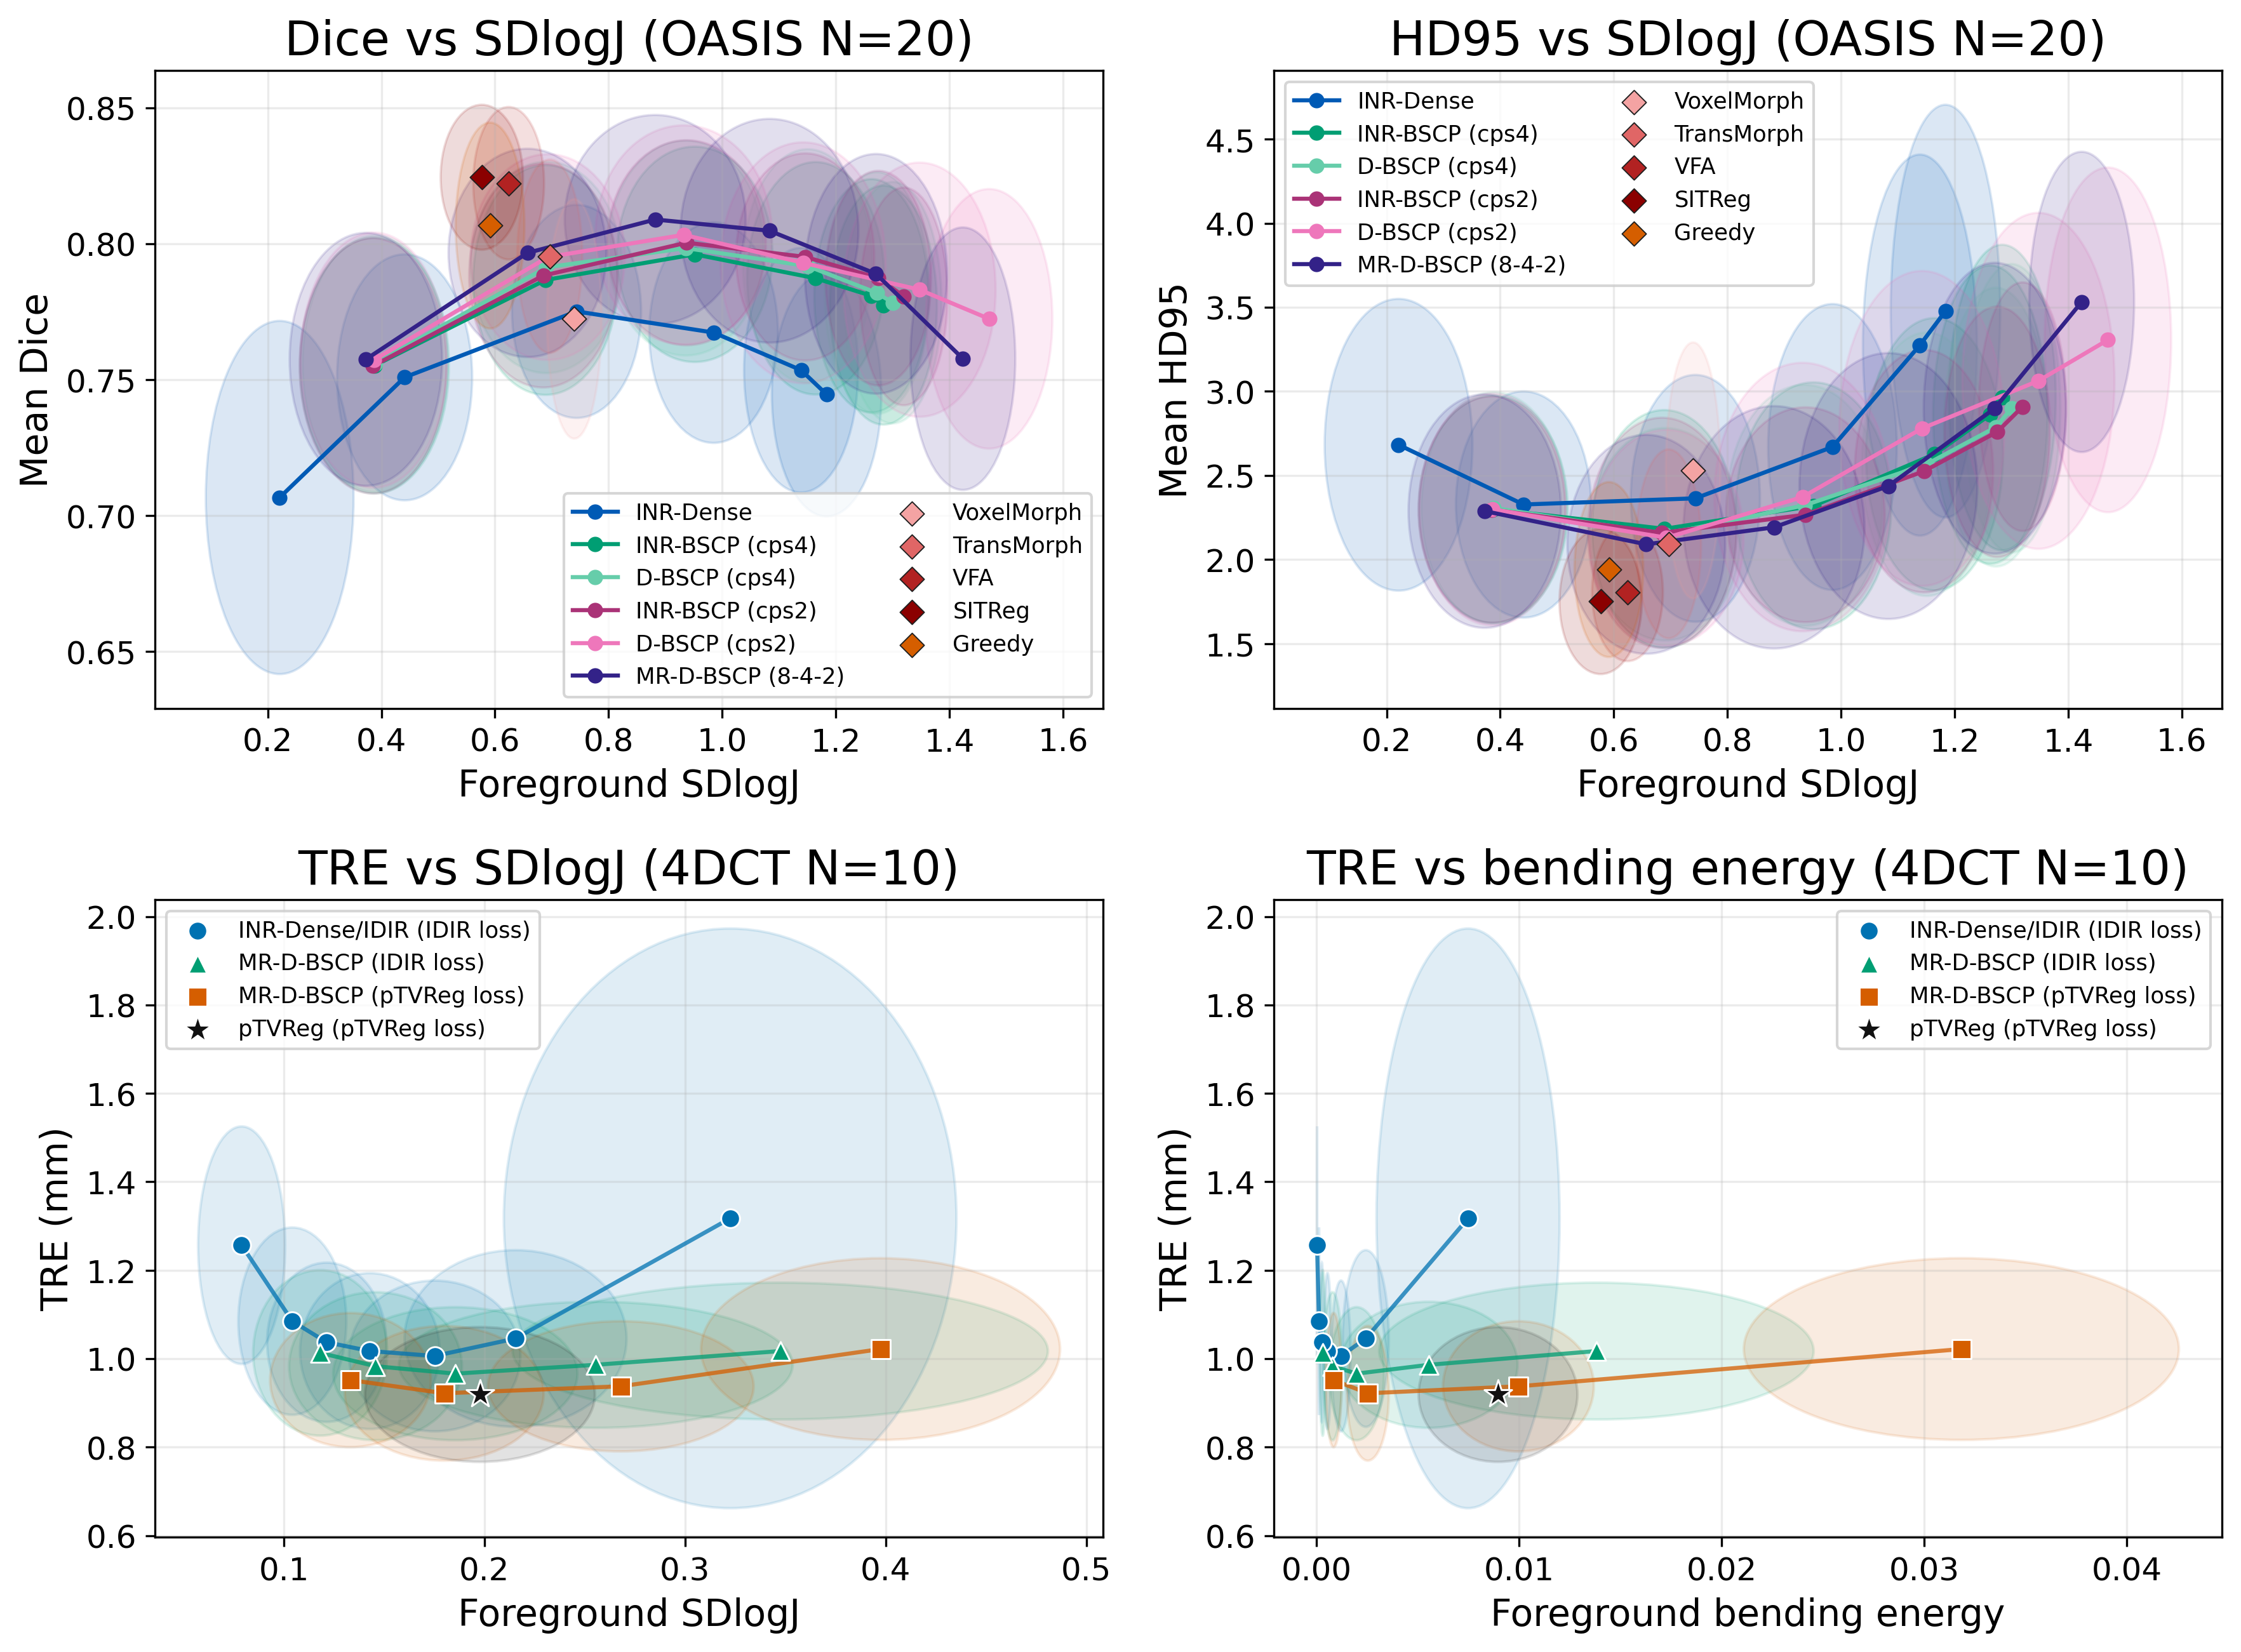

experiments/paper_artifacts/pareto_figure/v002_candidate/four_panel_composite/pareto_four_panel_composite_annotated_review.png


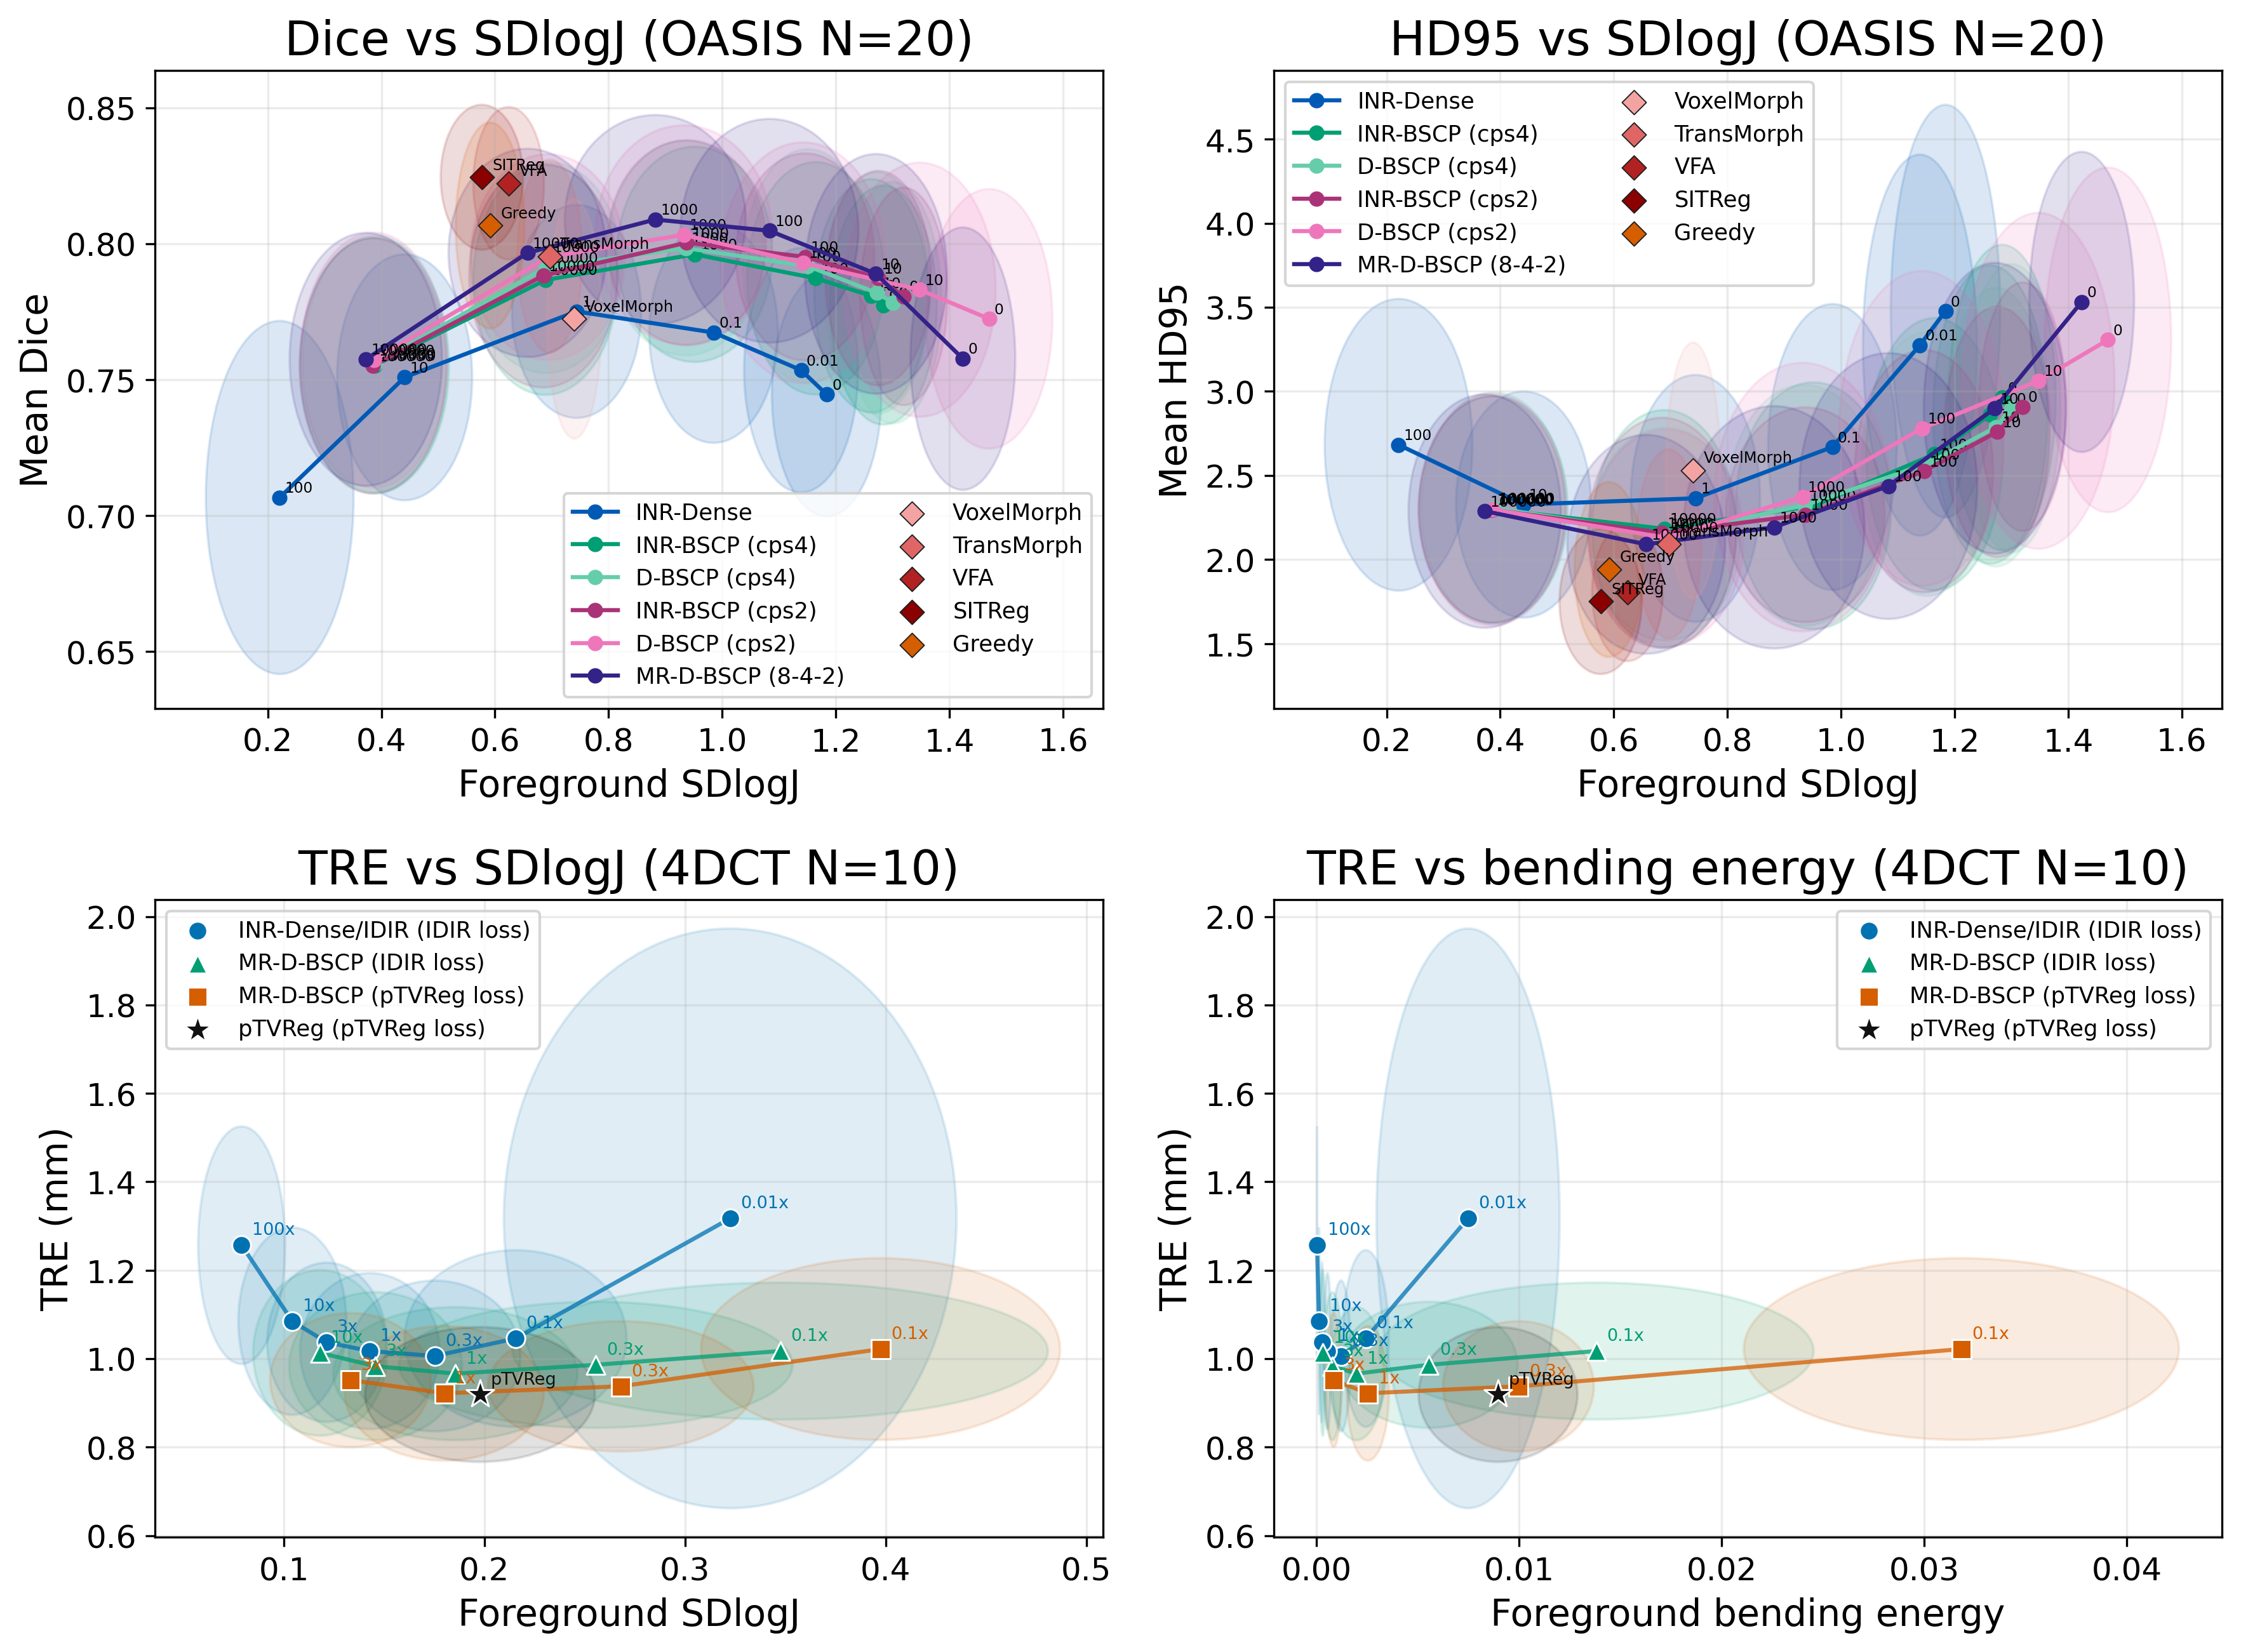

In [5]:
# Build, save, display, and record the composite figures
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved_outputs = []
for mode_name, mode in OUTPUTS.items():
    fig, axes = plt.subplots(2, 2, figsize=FIGURE_STYLE["figsize"], squeeze=False)
    for ax, spec in zip(axes.ravel(), PANELS):
        draw_panel(ax, spec, annotate=bool(mode["annotate"]))
    fig.subplots_adjust(
        wspace=FIGURE_STYLE["wspace"],
        hspace=FIGURE_STYLE["hspace"],
    )
    output_path = OUTPUT_DIR / mode["filename"]
    fig.savefig(output_path, dpi=FIGURE_STYLE["dpi"], bbox_inches="tight")
    plt.close(fig)
    saved_outputs.append(output_path)

manifest = {
    "artifact": "pareto_four_panel_composite",
    "source_version": SOURCE_VERSION,
    "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "source_files": {
        "oasis20": repo_rel(OASIS_SOURCE_CSV),
        "lungct10": repo_rel(LUNGCT_SOURCE_CSV),
        "method_nicknames": repo_rel(NICKNAME_CSV),
    },
    "outputs": [repo_rel(path) for path in saved_outputs],
    "output_formats": ["png"],
    "annotation_modes": {name: {"annotate": bool(spec["annotate"]), "filename": spec["filename"]} for name, spec in OUTPUTS.items()},
    "panels": PANELS,
    "style": FIGURE_STYLE,
    "label_conventions": {
        "logj_label_style": LOGJ_LABEL_STYLE,
        "logj_label": LOGJ_LABEL,
        "logj_label_options": LOGJ_LABEL_OPTIONS,
        "lungct_y_label": "TRE (mm)",
    },
    "oasis_method_color_overrides": OASIS_METHOD_COLOR_OVERRIDES,
    "lungct_method_color_overrides": LUNGCT_METHOD_COLOR_OVERRIDES,
    "lungct_method_marker_overrides": LUNGCT_METHOD_MARKER_OVERRIDES,
    "lungct_display_label_overrides": LUNGCT_DISPLAY_LABEL_OVERRIDES,
    "lungct_exclusion_rule": {
        "exclude_by_ratio": pareto.LUNGCT_EXCLUDE_BY_RATIO,
        "exclude_by_weight": pareto.LUNGCT_EXCLUDE_BY_WEIGHT,
    },
}
manifest_path = OUTPUT_DIR / "pareto_four_panel_composite_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")

print("Saved outputs:")
for path in saved_outputs:
    print(f"- {repo_rel(path)}")
print(f"- {repo_rel(manifest_path)}")

for path in saved_outputs:
    print(repo_rel(path))
    display(Image(filename=str(path)))